# 03 · Pipeline: de FS a ML (objetivo, partición temporal y la fuga)

> **Qué haces tú:** ejecutar el cuaderno entero y leer lo que sale. No hay código que escribir.

## Objetivo
Construir `ml_dataset`: **variables (FS) + objetivo (`y`) + partición**. Tres ideas:

1. **El objetivo `y`**: vale **1** si el lote alcanza el grado de especialidad (puntuación total >= 80) y **0** si no. Es lo único que mira el resultado de la cata, y es correcto: es la respuesta que el modelo debe anticipar.
2. **La partición temporal**: los lotes se reparten en `train` (el modelo aprende), `valid` (se comparan modelos y se elige) y `test` (se mide el elegido, una sola vez) **por el año de la cata**, nunca al azar.
3. **La fuga de información**: veremos con números reales por qué no se pueden usar las notas de cata.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160, 'display.max_columns', 30, 'display.max_colwidth', 70)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml». Así el cuaderno funciona se abra desde donde se abra.
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from cafe_mlops import config, db   # el paquete del proyecto: lo mismo que ejecutan las órdenes de la terminal

print('Proyecto listo.')
print('Base operacional:', config.DB_OPERACIONAL.name, '· base analítica:', config.DB.name)

con = db.conectar()
if not db.escalar(con, "SELECT COUNT(*) FROM sqlite_master WHERE type = 'table' AND name = 'master_lotes'"):
    raise FileNotFoundError('Falta master_lotes: ejecuta antes el cuaderno 01.')

from cafe_mlops import pipeline_ml

Proyecto listo.
Base operacional: cqi.db · base analítica: cafe.db


## 1. Construir FS y ML
`pipeline_ml.ejecutar()` lanza FS y ML juntos (ML se construye desde FS con la misma partición, así que no tiene sentido rehacer una sin la otra).
Como en el cuaderno 01, calcula una huella de entrada y, si nada cambió, dice `sin cambios`.

In [2]:
resultado_ml = pipeline_ml.ejecutar()

[pipeline_ml] ejecutando (huella de entrada 0bca8b260914)
  FS: fs_lote 1,190 lotes, 10 variables (catálogo: 10)
  ML: train    866 lotes (2010-2014) | especialidad 714 (82.4 %) | no 152
  ML: valid    197 lotes (2015-2015) | especialidad 185 (93.9 %) | no 12
  ML: test     127 lotes (2016-2016) | especialidad 122 (96.1 %) | no 5


## 2. La partición temporal deslizante
**¿Por qué por tiempo?** En producción el modelo se entrena con el **pasado** y predice lotes que llegan **después**. Si repartiéramos los lotes al azar, el
modelo vería lotes «del futuro» al entrenar y su nota sería demasiado optimista. Tampoco se reparte por orden de fila: el archivo viene ordenado por puntuación.

**¿Por qué «deslizante»?** Cuando llegan datos nuevos (versión 2), la ventana avanza un año: el modelo nuevo aprende también del año que antes servía para validar.
Los cortes salen de una sola función, `config.particiones_de(versión)`. Este es el reparto real de las dos versiones:

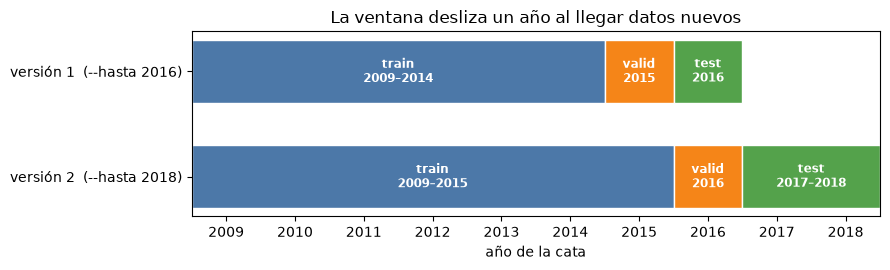

desde       hasta      
versión       1     2     1     2
partición                        
train      2009  2009  2014  2015
valid      2015  2016  2015  2016
test       2016  2017  2016  2018

In [3]:
import matplotlib.pyplot as plt

colores = {'train': '#4C78A8', 'valid': '#F58518', 'test': '#54A24B'}
etiquetas = {1: 'versión 1  (--hasta 2016)', 2: 'versión 2  (--hasta 2018)'}
fig, ax = plt.subplots(figsize=(9, 2.8))
tabla = []
for fila, version in enumerate((2, 1)):
    for nombre, (desde, hasta) in config.particiones_de(version).items():
        ax.barh(fila, hasta - desde + 1, left=desde - 0.5, color=colores[nombre], edgecolor='white', height=0.6)
        ax.text((desde + hasta) / 2, fila, f'{nombre}\n{desde}–{hasta}' if hasta > desde else f'{nombre}\n{desde}',
                ha='center', va='center', color='white', fontsize=8.5, fontweight='bold')
        tabla.append({'versión': version, 'partición': nombre, 'desde': desde, 'hasta': hasta})
ax.set_yticks([0, 1], [etiquetas[2], etiquetas[1]])
ax.set_xlim(2008.5, 2018.5)
ax.set_xticks(range(2009, 2019))
ax.set_xlabel('año de la cata')
ax.set_title('La ventana desliza un año al llegar datos nuevos')
plt.tight_layout()
plt.show()
pd.DataFrame(tabla).pivot(index='partición', columns='versión', values=['desde', 'hasta']).loc[['train', 'valid', 'test']]

`ml_particiones` guarda los cortes que se aplicaron a **estos** datos (la versión se deduce del último año de cata que hay en MASTER).
Y esta es la composición real de cada partición: cuántos lotes y **cuántos se quedaron sin especialidad** (los «negativos»).

In [4]:
display(pd.read_sql('SELECT particion, anio_desde, anio_hasta FROM ml_particiones ORDER BY anio_desde', con))
pd.read_sql("""
    SELECT particion, MIN(anio_cata) AS desde, MAX(anio_cata) AS hasta, COUNT(*) AS lotes,
           SUM(y) AS con_especialidad, COUNT(*) - SUM(y) AS sin_especialidad,
           ROUND(100.0 * (COUNT(*) - SUM(y)) / COUNT(*), 1) AS pct_sin_especialidad
    FROM ml_dataset GROUP BY particion ORDER BY MIN(anio_cata)""", con)

,particion,anio_desde,anio_hasta
0,train,2009,2014
1,valid,2015,2015
2,test,2016,2016


,particion,desde,hasta,lotes,con_especialidad,sin_especialidad,pct_sin_especialidad
0,train,2010,2014,866,714,152,17.6
1,valid,2015,2015,197,185,12,6.1
2,test,2016,2016,127,122,5,3.9


**Fíjate en lo difícil que es esto:** los lotes que **no** llegan a especialidad son pocos, y con los años son aún menos. Cuando una partición tiene muy pocos
negativos, **cualquier métrica oscila mucho** (lo verás en el cuaderno 04). Los gráficos muestran los lotes por año y el porcentaje que se queda sin especialidad.

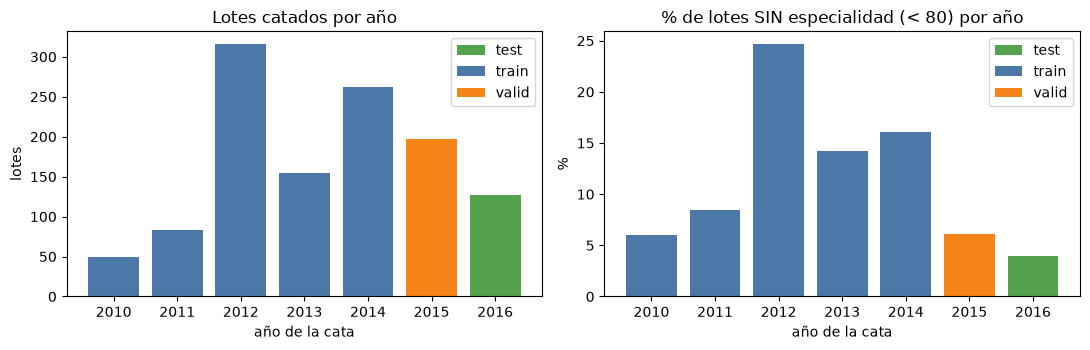

In [5]:
ml = pd.read_sql('SELECT * FROM ml_dataset ORDER BY lote_id', con)
por_anio = ml.groupby(['anio_cata', 'particion']).agg(lotes=('y', 'size'), sin_especialidad=('y', lambda s: int((s == 0).sum()))).reset_index()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for nombre, grupo in por_anio.groupby('particion'):
    a1.bar(grupo['anio_cata'], grupo['lotes'], color=colores[nombre], label=nombre)
    a2.bar(grupo['anio_cata'], 100 * grupo['sin_especialidad'] / grupo['lotes'], color=colores[nombre], label=nombre)
a1.set_title('Lotes catados por año')
a1.set_ylabel('lotes')
a2.set_title('% de lotes SIN especialidad (< 80) por año')
a2.set_ylabel('%')
for a in (a1, a2):
    a.set_xlabel('año de la cata')
    a.legend()
plt.tight_layout()
plt.show()

## 3. El objetivo, comprobado
`y` se calcula en SQL (`sql/ml/02_poblar_ml.sql`). Lo **recalculamos con pandas** desde la puntuación total de MASTER: si coinciden en todos los lotes, el SQL hace lo que dice.

In [6]:
total = pd.read_sql('SELECT lote_id, total_puntos FROM master_lotes', con).set_index('lote_id')['total_puntos']
y_pandas = (total.loc[ml['lote_id']] >= config.UMBRAL_ESPECIALIDAD).astype(int).to_numpy()
assert (ml['y'].to_numpy() == y_pandas).all()
print(f'y recalculado con pandas coincide en los {len(ml):,} lotes. Umbral: {config.UMBRAL_ESPECIALIDAD:g} puntos.')
print(f'Lotes con especialidad: {int(ml["y"].sum()):,} ({100 * ml["y"].mean():.1f} %)  ·  sin especialidad: {int((ml["y"] == 0).sum()):,}')

y recalculado con pandas coincide en los 1,190 lotes. Umbral: 80 puntos.
Lotes con especialidad: 1,021 (85.8 %)  ·  sin especialidad: 169


## 4. La fuga de información, con números
Vamos a **entrenar dos modelos iguales** (una regresión logística), con la **misma partición**, y a medir su **AUC** (la probabilidad de que el modelo dé más puntuación
a un lote de especialidad que a uno que no lo es; 0,5 es azar y 1 es perfecto):

- **Modelo A, honesto:** usa las variables de `ml_dataset`, que se conocen **al recibir el lote**.
- **Modelo B, con fuga:** usa las **diez notas de la cata**, que solo existen **después** de catar.

Primero, la razón de la fuga: la diferencia máxima entre el total y la suma de las notas (regla R04 de calidad del cuaderno 01).

In [7]:
diferencia = db.escalar(con, "SELECT valor FROM master_calidad WHERE regla LIKE 'R04%'")
print(f'Mayor diferencia entre Total.Cup.Points y la suma de las diez notas, en todos los lotes: {diferencia:g} puntos')

Mayor diferencia entre Total.Cup.Points y la suma de las diez notas, en todos los lotes: 0.5 puntos


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from cafe_mlops.modeling import preproceso

notas = pd.read_sql('SELECT cata_id AS lote_id, atributo, valor FROM raw_notas_cata', con)
notas = notas.pivot(index='lote_id', columns='atributo', values='valor').fillna(0.0).loc[ml['lote_id']].reset_index(drop=True)

experimentos = [
    ('A · variables al recibir el lote (honesto)', preproceso.preparar_X(ml), preproceso.construir_modelo(LogisticRegression(max_iter=2000))),
    ('B · las diez notas de cata (FUGA)', notas, make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
]
entrena = (ml['particion'] == 'train').to_numpy()
filas = []
for nombre, X, modelo in experimentos:
    modelo.fit(X[entrena], ml.loc[entrena, 'y'])
    fila = {'modelo': nombre, 'variables': X.shape[1]}
    for particion in ('valid', 'test'):
        m = (ml['particion'] == particion).to_numpy()
        fila[f'AUC {particion}'] = round(roc_auc_score(ml.loc[m, 'y'], modelo.predict_proba(X[m])[:, 1]), 3)
    filas.append(fila)
resultado_fuga = pd.DataFrame(filas).set_index('modelo')
resultado_fuga

,variables,AUC valid,AUC test
modelo,,,
A · variables al recibir el lote (honesto),10,0.572,0.752
B · las diez notas de cata (FUGA),15,0.985,0.993


**Cómo leerlo.** El modelo B «acierta» casi todo (AUC cercano a 1) porque, en el fondo, **suma las notas**: no predice nada, **calcula** el total.
Pero para un lote recién llegado **no hay notas**, así que ese modelo no se puede usar. El modelo A es el que el negocio necesita: tiene una nota mucho más modesta,
y esa es la **nota honesta**. Cuando un modelo parezca demasiado bueno, sospecha de una fuga.

Por eso el proyecto tiene una **prueba automática** que falla si alguna variable sale de las notas de cata o del total.

In [9]:
con.close()

## Resumen
- `ml_dataset` = variables + objetivo `y` (1 si el total es >= 80) + partición (`train`, `valid`, `test`).
- La partición es **temporal y deslizante**: los cortes dependen de la versión de los datos y salen de una única función de `config.py`.
- Los lotes sin especialidad son **pocos**, y eso hará oscilar las métricas.
- **Una fuga de información** (usar las notas de cata) da un modelo «perfecto» e inútil.

**Siguiente:** el cuaderno **04** entrena los modelos de verdad, los compara y los registra en MLflow.

## Para practicar
1. Con la versión 2 de los datos, ¿qué partición gana el año 2015? ¿Y qué año pasa de test a validación?
2. ¿Por qué el AUC del modelo B es casi perfecto aunque no sepa nada de café?